# 2 - Pattern Matching using Regex

> 📗 **About this browser version:** this notebook runs in JupyterLite, in your browser, so there is nothing to set up. The `data/` folder holds a sample of 200 of the 1,007 invoice PDFs in the original repository, which keeps the loops over every file quick in the browser. The sample includes a few invoices that the patterns do not match, as the full set does. The first code cell installs pdfplumber 0.9.0: newer versions need a library (`pypdfium2`) that cannot run in the browser, and the parts of pdfplumber these notebooks use work the same way in 0.9.0.

In [ ]:
# pdfplumber 0.9.0 runs in the browser; newer versions need pypdfium2, which does not
%pip install -q pdfplumber==0.9.0

import os
import pdfplumber
import re

In [ ]:
# Directory containing all PDF files
pdf_directory = "data/"
pdf_files = [os.path.join(pdf_directory, file) for file in os.listdir(pdf_directory) if file.endswith(".pdf")]

In [ ]:
pdf = pdfplumber.open(pdf_files[0])
page = pdf.pages[0]
text = page.extract_text()

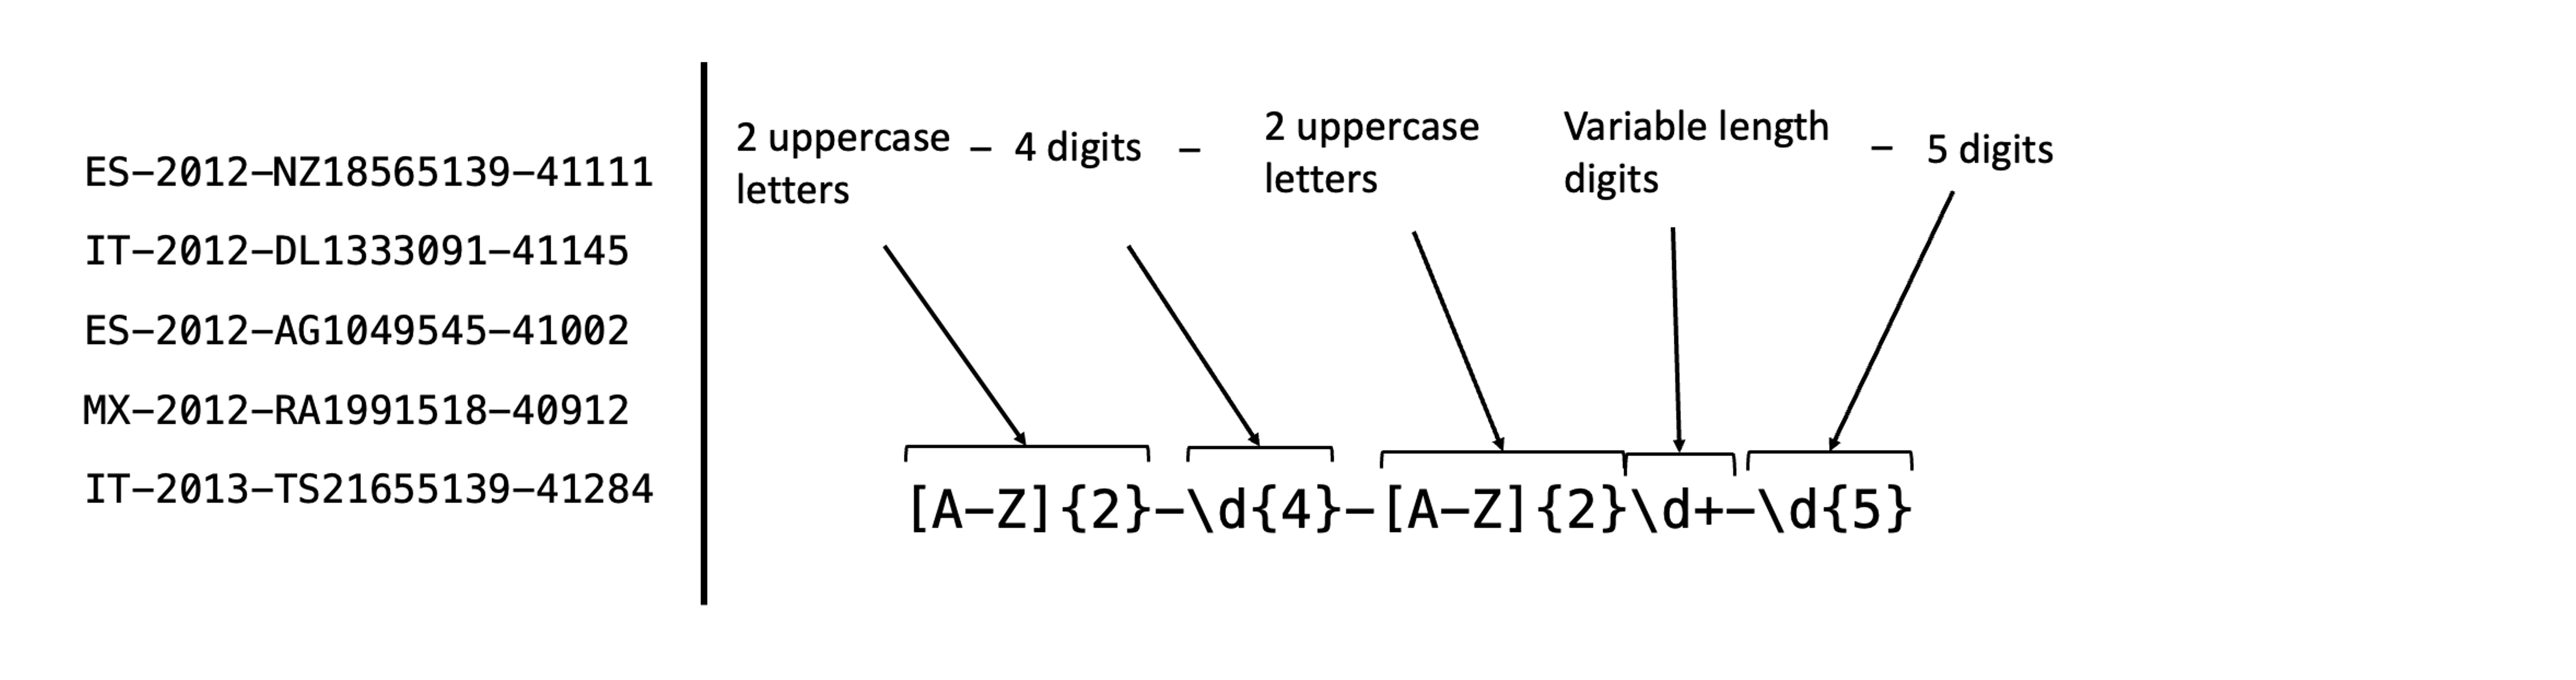
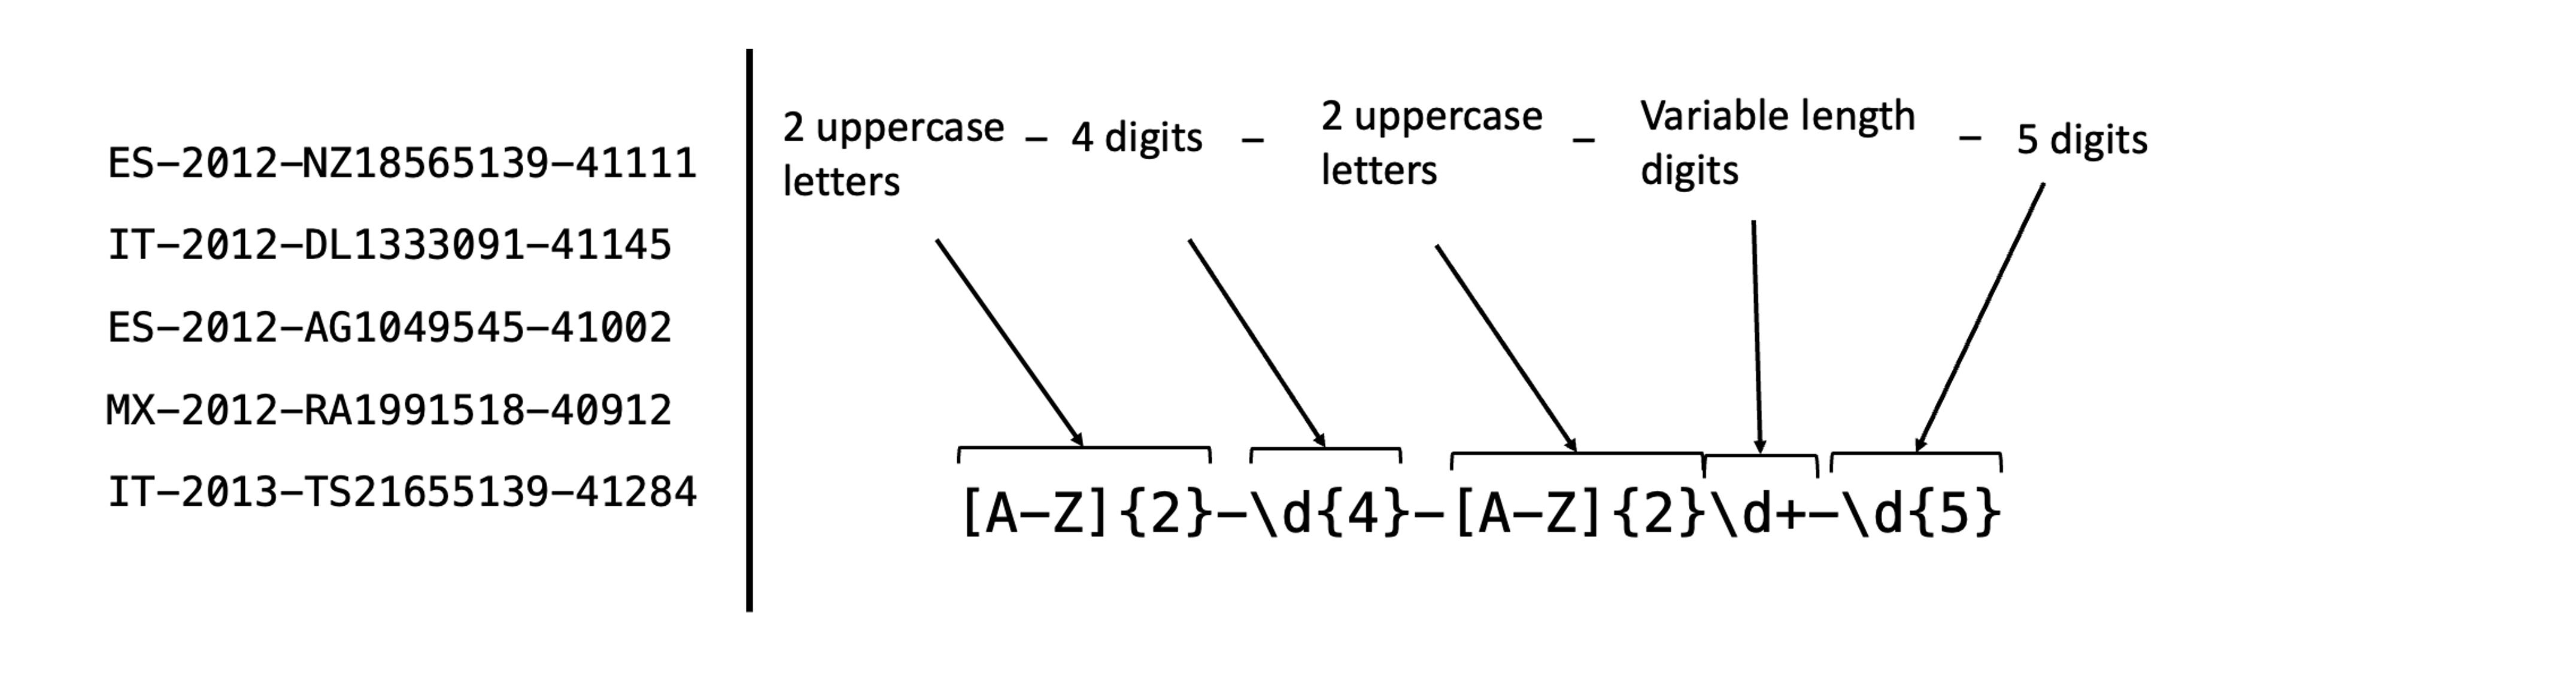

[Test Regex Pattern for Order ID](https://regex101.com/r/hDlxa8/1)

In [ ]:
orderid_pattern = r'[A-Z]{2}-\d{4}-[A-Z]{2}\d+-\d{5}'

In [ ]:
matches = re.search(orderid_pattern, text)
matches.group()

In [ ]:
# 'Total: $329.01'
total_pattern = r'Total: ([$\d,.]+)'

[Test Regex pattern for total](https://regex101.com/r/CkBHMQ/1)

In [ ]:
matches = re.search(total_pattern, text)
matches.group()

In [ ]:
matches.group(1)

In [ ]:
orderid_pattern = r'[A-Z]{2}-\d{4}-[A-Z]{2}\d*-\d{5}'
total_pattern = r'Total: ([$\d,.]+)'

order_data = []
for pdf in pdf_files:
    with pdfplumber.open(pdf) as pdf:
        for page in pdf.pages:
            text = page.extract_text()                                  
            if re.search(orderid_pattern, text):
                orderid = re.search(orderid_pattern, text).group()
            else:
                orderid = None
            if re.search(total_pattern, text):
                total = re.search(total_pattern, text).group(1)
            else:
                total = None
            order_data.append((orderid, total))


In [ ]:
order_data[:5]

In [ ]:
# TODO- Fill out the pattern code for all the other relevant fields

orderid_pattern = r'[A-Z]{2}-\d{4}-[A-Z]{2}\d{5,}-\d{5}'
total_pattern = r'Total: ([$\d,.]+)'
shipmode_pattern = r'PASTE YOUR PATTERN HERE'
date_pattern = r'PASTE YOUR PATTERN HERE'
itemcode_pattern = r'PASTE YOUR PATTERN HERE'
shipping_pattern = r'PASTE YOUR PATTERN HERE'


In [ ]:
order_data = []
for pdf in pdf_files:
    with pdfplumber.open(pdf) as pdf:
        for page in pdf.pages:
            text = page.extract_text()                                
            
            orderid = re.search(orderid_pattern, text).group() if re.search(orderid_pattern, text) else None
            date = re.search(date_pattern, text).group() if re.search(date_pattern, text) else None
            itemcode = re.search(itemcode_pattern, text).group() if re.search(itemcode_pattern, text) else None
            shipmode = re.search(shipmode_pattern, text).group(1) if re.search(shipmode_pattern, text) else None
            shipping = re.search(shipping_pattern, text).group(1) if re.search(shipping_pattern, text) else None
            total = re.search(total_pattern, text).group(1) if re.search(total_pattern, text) else None
            
            order_data.append((orderid, date, itemcode, shipmode, shipping, total))

In [ ]:
order_data[:5]